# Optical Transfer Function: Modulation

> Part of *PHYS 0241: Biomedical Imaging* (Prof. Michael E. Durst, Middlebury College). The [textbook page for this notebook](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/python/ch05/ch05-12.html) shows the rendered version together with the pre-rendered animations (course password required).
>
> **Start here:** no setup is needed for this notebook. In Google Colab, choose **File > Save a copy in Drive** to keep your changes.
>
> *Provided for academic use in PHYS 0241; please do not repost or redistribute ([terms of use](https://github.com/durstme/textbook-biomedicalimaging-notebooks/blob/main/LICENSE.md)).*

## Plot

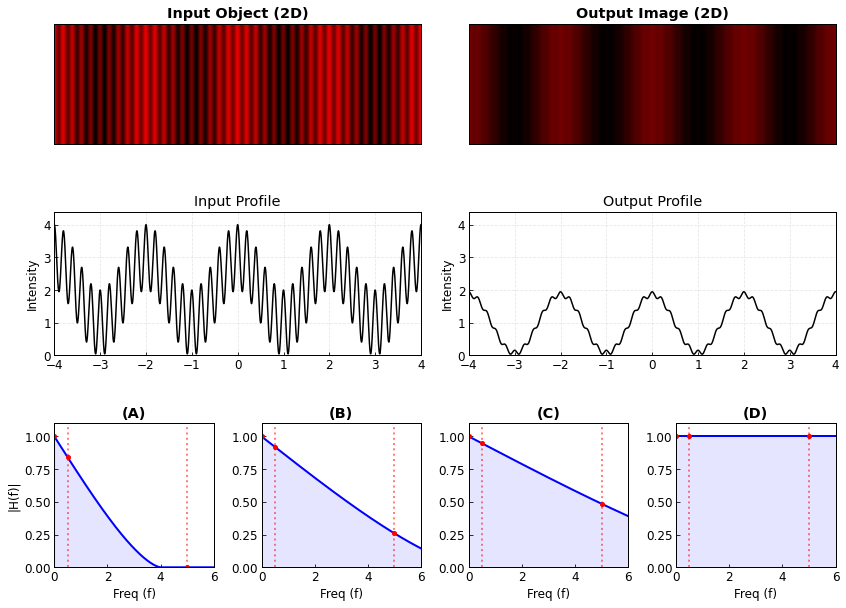

In [39]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import matplotlib.gridspec as gridspec

# ==========================================
# 1. Configuration & Style
# ==========================================
plot_params = {
    'font.size': 12,
    'font.family': 'sans-serif',
    'axes.linewidth': 1.0,
    'lines.linewidth': 2.0,
    'figure.titlesize': 16,
    'xtick.direction': 'in',
    'ytick.direction': 'in',
}
plt.rcParams.update(plot_params)

# Custom Red Laser Colormap
colors = [(0, 0, 0), (1, 0, 0)] # Black to Red
laser_cmap = LinearSegmentedColormap.from_list("laser_red", colors)

# ==========================================
# 2. Physics & Data Generation
# ==========================================
def generate_signal(x, freqs, weights):
    """
    Generates an intensity profile.
    """
    # DC component
    intensity = np.zeros_like(x) 
    
    f1, f2, f3 = freqs
    w1, w2, w3 = weights
    
    # Cosine components (Amplitude 0.3 to ensure sum < 0)
    component_1 = w1 * np.cos(2 * np.pi * f1 * x)
    component_2 = w2 * np.cos(2 * np.pi * f2 * x)
    component_3 = w3 * np.cos(2 * np.pi * f3 * x)
    
    total_intensity = intensity + component_1 + component_2 + component_3 + w1 + w2 + w3  # Add weights to ensure positive intensity
    
    return total_intensity

def get_standard_otf(f_axis, cutoff, coherence_type):
    """
    Generates standard Optical Transfer Functions.
    f_axis: frequency array
    cutoff: cutoff frequency
    coherence_type: 'coherent' (Square) or 'incoherent' (Chinese Hat / Chat)
    """
    if coherence_type == 'coherent':
        # Rect function: 1 if |f| < cutoff, else 0
        otf = np.where(np.abs(f_axis) <= cutoff, 1.0, 0.0)
        return otf
        
    elif coherence_type == 'incoherent':
        # 2D Circular Aperture OTF (The "Chat" function)
        # H(rho) = (2/pi) * [arccos(rho) - rho * sqrt(1 - rho^2)]
        # where rho = f / cutoff_freq
        
        # Avoid division by zero or domain errors
        rho = np.abs(f_axis) / (cutoff + 1e-9)
        
        # Clip rho to [0, 1] for calculation, then mask out >1
        rho_clamped = np.clip(rho, 0, 1)
        
        val = (2 / np.pi) * (np.arccos(rho_clamped) - rho_clamped * np.sqrt(1 - rho_clamped**2))
        
        # Set values exactly to 0 where f > cutoff
        otf = np.where(rho <= 1.0, val, 0.0)
        
        return otf
        
    return np.zeros_like(f_axis)

def get_weights_from_otf(freqs, cutoff, coherence_type):
    """ Calculates specific weights for the discrete frequencies based on the OTF. """
    f_axis = np.array(freqs)
    weights = get_standard_otf(f_axis, cutoff, coherence_type)
    return tuple(weights)

# ==========================================
# 3. Main Plotting Function
# ==========================================
def create_optical_puzzle(object_freqs, object_weights, title_text, correct_cutoff, correct_type):
    """
    object_weights: (w1, w2, w3) for the image generation
    correct_cutoff: The cutoff frequency that produces these weights (approx)
    correct_type: 'coherent' or 'incoherent'
    """
    
    # --- Setup Data ---
    x_limit = 4
    x = np.linspace(-x_limit, x_limit, 2048)
    freqs = object_freqs
    
    # 1. Generate OBJECT (Input) - All frequencies present
    obj_1d = generate_signal(x, freqs, object_weights)
    obj_2d = np.tile(obj_1d, (100, 1))
    
    # 2. Generate IMAGE (Output) - Filtered by OTF
    image_weights = np.array(get_weights_from_otf(freqs, correct_cutoff, correct_type)) * np.array(object_weights)
    img_1d = generate_signal(x, freqs, image_weights)
    img_2d = np.tile(img_1d, (100, 1))

    # --- Setup Figure Layout ---
    fig = plt.figure(figsize=(14, 10))
    # Grid: 3 Rows, 4 Columns
    gs = gridspec.GridSpec(3, 4, height_ratios=[1, 1.2, 1.2], hspace=0.5, wspace=0.3)

    # ==========================================
    # ROW 1: 2D IMAGES (Density Plots)
    # ==========================================

    # Calculate common Y-limit
    common_ymax = max(np.max(obj_1d), np.max(img_1d)) * 1.1

    # Left: Object 2D
    ax_obj_2d = fig.add_subplot(gs[0, :2])
    ax_obj_2d.imshow(obj_2d, extent=[-x_limit, x_limit, 0, 1], aspect='auto', cmap=laser_cmap, vmin=0, vmax=common_ymax)
    ax_obj_2d.set_title("Input Object (2D)", fontweight='bold')
    ax_obj_2d.set_yticks([])
    ax_obj_2d.set_xticks([])
    
    # Right: Image 2D
    ax_img_2d = fig.add_subplot(gs[0, 2:])
    ax_img_2d.imshow(img_2d, extent=[-x_limit, x_limit, 0, 1], aspect='auto', cmap=laser_cmap, vmin=0, vmax=common_ymax)
    ax_img_2d.set_title("Output Image (2D)", fontweight='bold')
    ax_img_2d.set_yticks([])
    ax_img_2d.set_xticks([])

    # ==========================================
    # ROW 2: 1D PROFILES (Line Plots)
    # ==========================================
    

    
    # Left: Object 1D
    ax_obj_1d = fig.add_subplot(gs[1, :2])
    ax_obj_1d.plot(x, obj_1d, 'k', linewidth=1.5)
    ax_obj_1d.set_title("Input Profile")
    ax_obj_1d.set_xlim(-x_limit, x_limit)
    ax_obj_1d.set_ylim(0, common_ymax)
    ax_obj_1d.grid(True, linestyle='--', alpha=0.3)
    ax_obj_1d.set_ylabel("Intensity")
    
    # Right: Image 1D
    ax_img_1d = fig.add_subplot(gs[1, 2:], sharey=ax_obj_1d)
    ax_img_1d.plot(x, img_1d, 'k', linewidth=1.5)
    ax_img_1d.set_title("Output Profile")
    ax_img_1d.set_xlim(-x_limit, x_limit)
    # y-lim is shared via sharey, but setting it explicitly is safe too
    ax_img_1d.set_ylim(0, common_ymax)
    ax_img_1d.grid(True, linestyle='--', alpha=0.3)
    ax_img_1d.set_ylabel("Intensity")

    # ==========================================
    # ROW 3: OTF OPTIONS (Standard Shapes)
    # ==========================================
    
    f_axis = np.linspace(0, 7, 500)
    labels = ['(A)', '(B)', '(C)', '(D)']
    
    # Generate 4 Scenarios
    scenarios = []
    
    # Define an "Alternative" cutoff (Distractor)
    # If correct is high (>3.5), distractor is low (2.0)
    # If correct is low (<3.5), distractor is high (4.0)
    # alt_cutoff = 2.0 if correct_cutoff >= 3.5 else 4.0
    alt_type = 'incoherent' if correct_type == 'coherent' else 'coherent'
    
    # 1. Correct Answer
    scenarios.append({
        'y': get_standard_otf(f_axis, 4, correct_type),
        'label': f"Correct",
    })
    
    # 2. Distractor 1: Same Type, Wrong Cutoff
    scenarios.append({
        'y': get_standard_otf(f_axis, 8, correct_type),
        'label': f"Wrong Cutoff",
    })
    
    # 3. Distractor 2: Wrong Type, Correct Cutoff
    scenarios.append({
        'y': get_standard_otf(f_axis, 12, correct_type),
        'label': f"Wrong Type",
    })
    
    # 4. Distractor 3: Wrong Type, Wrong Cutoff
    scenarios.append({
        'y': get_standard_otf(f_axis, 7, alt_type),
        'label': f"Wrong Everything",
    })

    # Plot the 4 options
    for i in range(4):
        ax = fig.add_subplot(gs[2, i])
        
        # Plot OTF
        y_vals = scenarios[i]['y']
        ax.plot(f_axis, y_vals, 'b-', linewidth=2)
        ax.fill_between(f_axis, y_vals, alpha=0.1, color='b')
        
        # Mark Frequencies
        for f, w in zip(freqs, object_weights):
            ax.axvline(x=f, color='r', linestyle=':', alpha=0.5)
            # Optional: Plot dots on the CORRECT plot to show alignment
            curve_val = np.interp(f, f_axis, y_vals)
            ax.plot(f, curve_val, 'ro', markersize=4)

        ax.set_ylim(0, 1.1)
        ax.set_xlim(0, 6)
        ax.set_title(labels[i], fontweight='bold')
        ax.set_xlabel("Freq (f)")
        if i == 0: ax.set_ylabel("|H(f)|")

    # Overall Title
    # fig.suptitle(f"Optical Transfer Function Puzzle: {title_text}", fontsize=18, y=0.98)
    
    plt.show()
    return fig

fig1 = create_optical_puzzle(
    object_freqs=(0.0, 0.5, 5.0),
    object_weights=(0, 1, 1), 
    title_text="Incoherent Imaging (2D Circular Aperture)",
    correct_cutoff=6.0,
    correct_type='incoherent'
)

## Find Image Given OTF

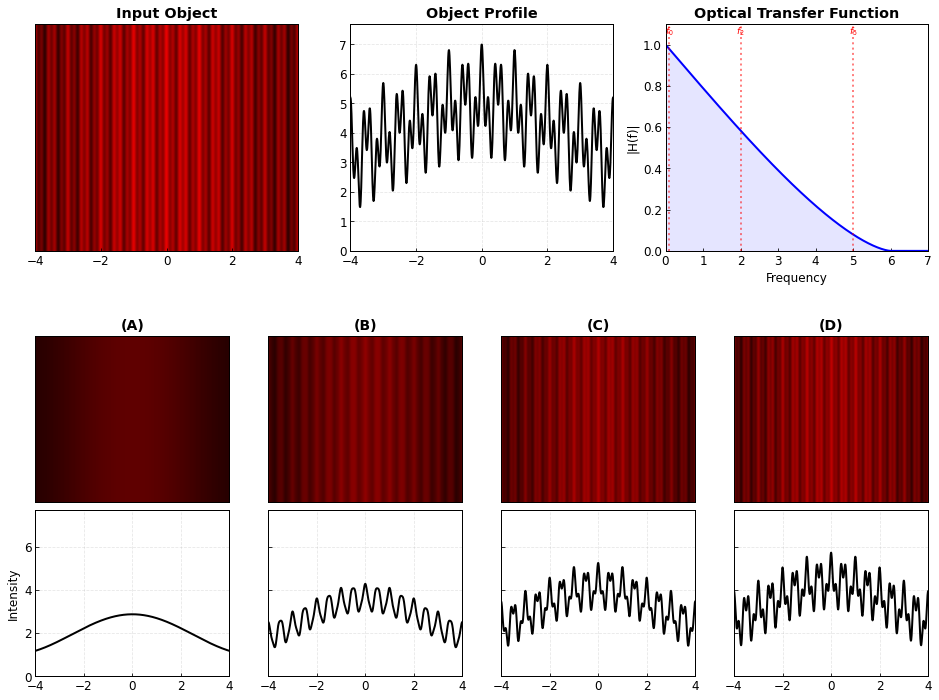

In [35]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import matplotlib.gridspec as gridspec

# ==========================================
# 1. Configuration & Style
# ==========================================
plot_params = {
    'font.size': 12,
    'font.family': 'sans-serif',
    'axes.linewidth': 1.0,
    'lines.linewidth': 2.0,
    'figure.titlesize': 16,
    'xtick.direction': 'in',
    'ytick.direction': 'in',
}
plt.rcParams.update(plot_params)

# Custom Red Laser Colormap
colors = [(0, 0, 0), (1, 0, 0)] 
laser_cmap = LinearSegmentedColormap.from_list("laser_red", colors)

# ==========================================
# 2. Physics & Data Generation
# ==========================================
def generate_signal(x, freqs, weights):
    """ Generates 1D intensity profile. """
    intensity = np.ones_like(x)
    f1, f2, f3 = freqs
    w1, w2, w3 = weights
    
    # Amplitudes
    c1 = w1 * np.cos(2 * np.pi * f1 * x)
    c2 = w2 * np.cos(2 * np.pi * f2 * x)
    c3 = w3 * np.cos(2 * np.pi * f3 * x)
    
    return intensity + c1 + c2 + c3 + w1 + w2 + w3  # Ensure positive intensity

def get_otf_curve(f_axis, cutoff, coherence_type):
    """ Returns the OTF curve array for plotting the input filter. """
    if coherence_type == 'coherent':
        return np.where(np.abs(f_axis) <= cutoff, 1.0, 0.0)
    elif coherence_type == 'incoherent':
        # Chat function (2D circular aperture autocorrelation)
        rho = np.abs(f_axis) / (cutoff + 1e-9)
        rho = np.clip(rho, 0, 1)
        val = (2 / np.pi) * (np.arccos(rho) - rho * np.sqrt(1 - rho**2))
        return np.where(rho < 1.0, val, 0.0)
    return np.zeros_like(f_axis)

def get_weights_from_otf(freqs, cutoff, coherence_type):
    """ Calculates specific weights for the discrete frequencies based on the OTF. """
    f_axis = np.array(freqs)
    weights = get_otf_curve(f_axis, cutoff, coherence_type)
    return tuple(weights)

# ==========================================
# 3. Main Plotting Function
# ==========================================
def create_image_selection_puzzle(object_freqs, object_weights, cutoff, coherence_type, title_text):
    
    # --- Setup Data ---
    x_limit = 4
    x = np.linspace(-x_limit, x_limit, 1000)
    freqs = object_freqs
    f_axis = np.linspace(0, 8, 500)
    
    # 1. Define Input Object (1D & 2D)
    obj_weights = object_weights
    obj_1d = generate_signal(x, freqs, obj_weights)
    obj_2d = np.tile(obj_1d, (100, 1))
    
    # 2. Define The Filter (OTF)
    otf_curve = get_otf_curve(f_axis, cutoff, coherence_type)
    
    # 3. Define The Choices (Candidate Images)
    choices = []
    
    # (A) The Correct Answer
    choices.append({'w': get_weights_from_otf(freqs, 2, coherence_type), 'label': 'Correct'})
    
    # (B) Distractor: The Original Object (No Filtering)
    choices.append({'w': get_weights_from_otf(freqs, 6, coherence_type), 'label': 'No Filter'})
    
    # (C) Distractor: Excessive Blur (Low Pass, Cutoff ~2.0)
    # Force a low cutoff
    choices.append({'w': get_weights_from_otf(freqs, 10, coherence_type), 'label': 'Too Blurry'})

    # (D) Distractor: High Pass / Edge Enhancement (Inverted weights)
    # Just make high freq stronger than low freq
    choices.append({'w': get_weights_from_otf(freqs, 14, coherence_type), 'label': 'High Pass'})
    
    # Note: Shuffle choices in a real app.
    
    # --- Setup Figure Layout ---
    fig = plt.figure(figsize=(16, 12))
    
    # We need a layout that handles:
    # Top: Inputs (3 columns: Obj 2D, Obj 1D, OTF)
    # Bottom: Outputs (4 columns, 2 rows each: Img 2D, Img 1D)
    
    # Outer Grid: 2 main sections (Top, Bottom)
    outer_gs = gridspec.GridSpec(2, 1, height_ratios=[1, 1.5], hspace=0.3)
    
    # --- TOP SECTION: INPUTS ---
    top_gs = gridspec.GridSpecFromSubplotSpec(1, 3, subplot_spec=outer_gs[0], wspace=0.2)

    # Calculate common Y-limit
    common_ymax = np.max(obj_1d) * 1.1
    
    # 1. Input Object 2D
    ax_top_1 = fig.add_subplot(top_gs[0])
    ax_top_1.imshow(obj_2d, extent=[-x_limit, x_limit, 0, 1], aspect='auto', cmap=laser_cmap, vmin=0, vmax=common_ymax)
    ax_top_1.set_title("Input Object", fontweight='bold')
    ax_top_1.set_yticks([])
    
    # 2. Input Object 1D
    ax_top_2 = fig.add_subplot(top_gs[1])
    ax_top_2.plot(x, obj_1d, 'k')
    ax_top_2.set_title("Object Profile", fontweight='bold')
    ax_top_2.set_ylim(0, common_ymax)
    ax_top_2.set_xlim(-x_limit, x_limit)
    ax_top_2.grid(True, linestyle='--', alpha=0.3)
    
    # 3. The OTF (The Rule)
    ax_top_3 = fig.add_subplot(top_gs[2])
    ax_top_3.plot(f_axis, otf_curve, 'b-', linewidth=2)
    ax_top_3.fill_between(f_axis, otf_curve, color='b', alpha=0.1)
    # Mark the signal frequencies
    for f in freqs:
        ax_top_3.axvline(x=f, color='r', linestyle=':', alpha=0.5)
        ax_top_3.text(f, 1.05, f"$f_{int(f)}$", ha='center', fontsize=9, color='r')
        
    ax_top_3.set_title("Optical Transfer Function", fontweight='bold')
    ax_top_3.set_ylim(0, 1.1)
    ax_top_3.set_xlim(0, 7)
    ax_top_3.set_xlabel("Frequency")
    ax_top_3.set_ylabel("|H(f)|")

    # --- BOTTOM SECTION: CHOICES ---
    # 2 Rows (Image, Profile) x 4 Columns (A, B, C, D)
    btm_gs = gridspec.GridSpecFromSubplotSpec(2, 4, subplot_spec=outer_gs[1], height_ratios=[1, 1], hspace=0.05, wspace=0.2)
    
    choice_labels = ['(A)', '(B)', '(C)', '(D)']
    
    for i, choice in enumerate(choices):
        # Generate Data
        img_1d = generate_signal(x, freqs, choice['w'])
        img_2d = np.tile(img_1d, (100, 1))
        
        # Plot 2D Image (Top row of bottom section)
        ax_img = fig.add_subplot(btm_gs[0, i])
        ax_img.imshow(img_2d, extent=[-x_limit, x_limit, 0, 1], aspect='auto', cmap=laser_cmap, vmin=0, vmax=common_ymax)
        ax_img.set_title(choice_labels[i], fontweight='bold', fontsize=14)
        ax_img.set_yticks([])
        ax_img.set_xticks([]) # Hide x ticks for 2D image, let 1D plot show them
        
        # Plot 1D Profile (Bottom row of bottom section)
        ax_prof = fig.add_subplot(btm_gs[1, i])
        ax_prof.plot(x, img_1d, 'k')
        ax_prof.set_ylim(0, common_ymax) # Match Object Scale
        ax_prof.set_xlim(-x_limit, x_limit)
        ax_prof.grid(True, linestyle='--', alpha=0.3)
        if i == 0:
            ax_prof.set_ylabel("Intensity")
        else:
            ax_prof.set_yticklabels([]) # Hide Y labels for inner plots
            
    # fig.suptitle(f"Select the Result: {title_text}", fontsize=20, y=0.98)
    plt.show()

    return fig

# ==========================================
# 4. Execute
# ==========================================

# Example: Incoherent imaging with a moderate cutoff
# This should result in blurring (lower contrast) but not total loss of the signal.
fig2 = create_image_selection_puzzle(
    object_freqs=(0.1, 2.0, 5.0),
    object_weights=(1, 1, 1),
    cutoff=6.0, 
    coherence_type='incoherent', 
    title_text="Incoherent Aperture (Cutoff=4)"
)